In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [47]:
data = pd.read_csv("../data/Sales Dataset.csv")


In [48]:
data.head()

,Order ID,Amount,Profit,Quantity,Category,Sub-Category,PaymentMode,Order Date,CustomerName,State,City,Year-Month
0,B-26776,9726,1275,5,Electronics,Electronic Games,UPI,2023-06-27,David Padilla,Florida,Miami,2023-06
1,B-26776,9726,1275,5,Electronics,Electronic Games,UPI,2024-12-27,Connor Morgan,Illinois,Chicago,2024-12
2,B-26776,9726,1275,5,Electronics,Electronic Games,UPI,2021-07-25,Robert Stone,New York,Buffalo,2021-07
3,B-26776,4975,1330,14,Electronics,Printers,UPI,2023-06-27,David Padilla,Florida,Miami,2023-06
4,B-26776,4975,1330,14,Electronics,Printers,UPI,2024-12-27,Connor Morgan,Illinois,Chicago,2024-12


In [49]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1194 entries, 0 to 1193
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Order ID      1194 non-null   object
 1   Amount        1194 non-null   int64 
 2   Profit        1194 non-null   int64 
 3   Quantity      1194 non-null   int64 
 4   Category      1194 non-null   object
 5   Sub-Category  1194 non-null   object
 6   PaymentMode   1194 non-null   object
 7   Order Date    1194 non-null   object
 8   CustomerName  1194 non-null   object
 9   State         1194 non-null   object
 10  City          1194 non-null   object
 11  Year-Month    1194 non-null   object
dtypes: int64(3), object(9)
memory usage: 112.1+ KB


In [50]:
data.shape

(1194, 12)

In [51]:
data.describe()

,Amount,Profit,Quantity
count,1194.000000,1194.000000,1194.000000
mean,5178.089615,1348.992462,10.674204
std,2804.921955,1117.992573,5.777102
min,508.000000,50.000000,1.000000
25%,2799.000000,410.000000,6.000000
50%,5152.000000,1014.000000,11.000000
75%,7626.000000,2035.000000,16.000000
max,9992.000000,4930.000000,20.000000


In [52]:
data.isnull().sum()

Order ID        0
Amount          0
Profit          0
Quantity        0
Category        0
Sub-Category    0
PaymentMode     0
Order Date      0
CustomerName    0
State           0
City            0
Year-Month      0
dtype: int64

In [53]:
data.duplicated().sum()

np.int64(0)

In [54]:
print(data.describe(include="object"))

       Order ID   Category Sub-Category PaymentMode  Order Date  \
count      1194       1194         1194        1194        1194   
unique      547          3           12           5         648   
top     B-26032  Furniture       Tables  Debit Card  2022-12-08   
freq         12        407          122         260           8   

             CustomerName     State     City Year-Month  
count                1194      1194     1194       1194  
unique                802         6       18         61  
top     Michael Rodriguez  New York  Buffalo    2022-12  
freq                    4       226       90         45  


In [55]:
print(data["Order ID"].value_counts().head(10))


Order ID
B-26032    12
B-26489    12
B-25465    12
B-26279    10
B-25715     9
B-26332     9
B-25916     8
B-26470     8
B-26554     8
B-25369     8
Name: count, dtype: int64


In [56]:
data["Order Date"] = pd.to_datetime(
    data["Order Date"], errors="coerce"
)


In [57]:
data.dtypes

Order ID                object
Amount                   int64
Profit                   int64
Quantity                 int64
Category                object
Sub-Category            object
PaymentMode             object
Order Date      datetime64[ns]
CustomerName            object
State                   object
City                    object
Year-Month              object
dtype: object

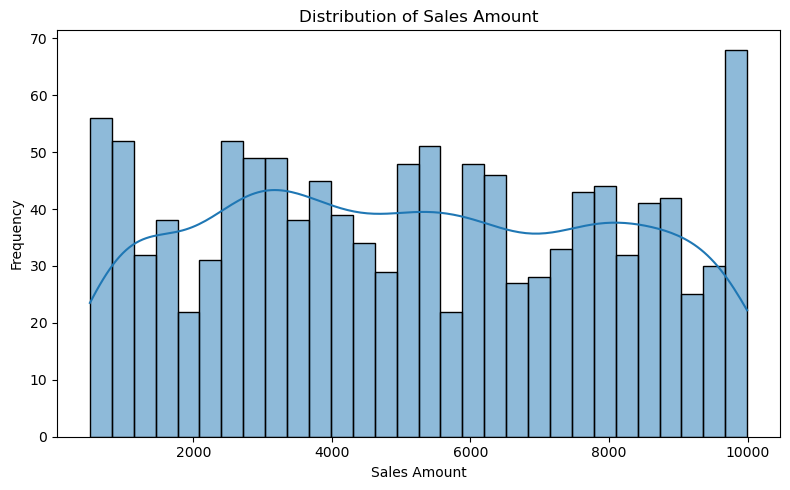

In [58]:
plt.figure(figsize=(8, 5))

sns.histplot(data["Amount"], bins=30, kde=True)

plt.title("Distribution of Sales Amount")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

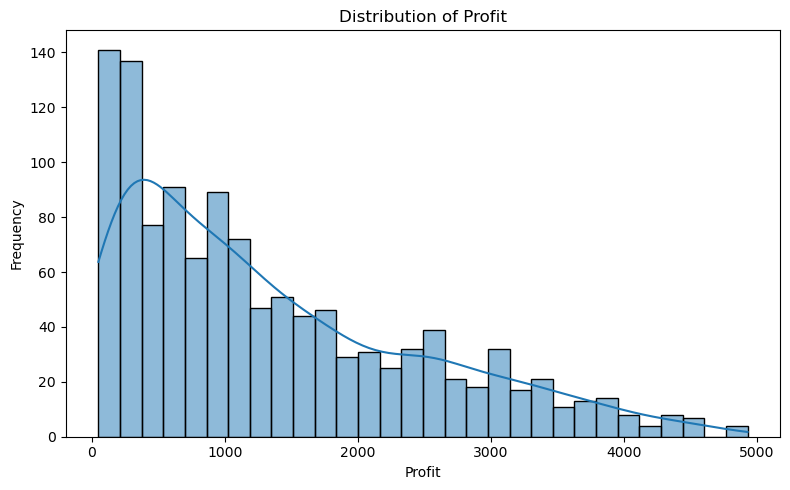

In [59]:
plt.figure(figsize=(8, 5))

sns.histplot(data["Profit"], bins=30, kde=True)

plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

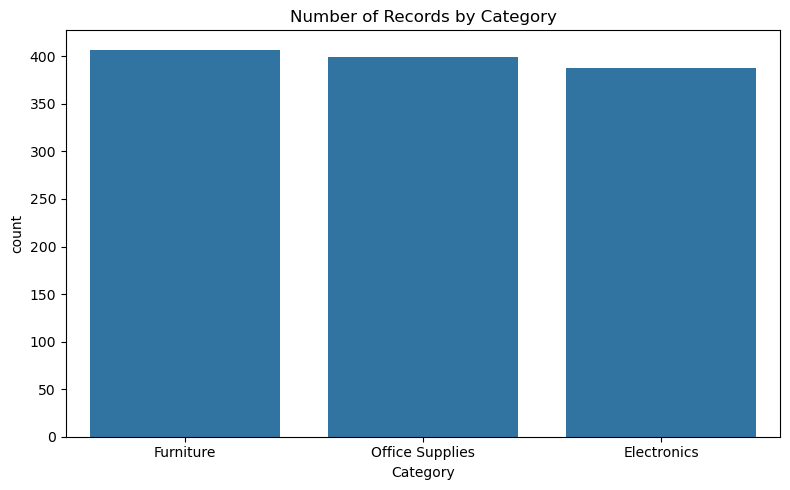

In [60]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="Category",
    order=data["Category"].value_counts().index
)

plt.title("Number of Records by Category")
plt.xticks()
plt.tight_layout()
plt.show()

Category
Office Supplies    2089510
Electronics        2054456
Furniture          2038673
Name: Amount, dtype: int64


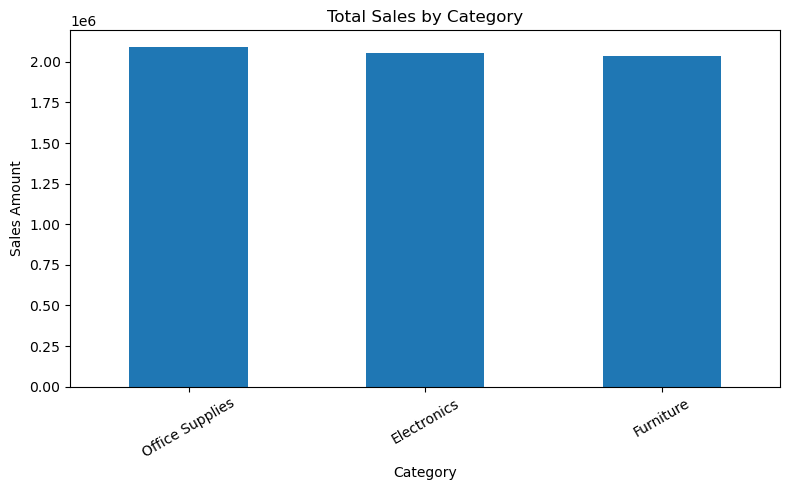

In [61]:
sales_category = data.groupby(
    "Category"
)["Amount"].sum().sort_values(ascending=False)

print(sales_category)

sales_category.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Category",
    ylabel="Sales Amount",
    xlabel="Category"
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [62]:
clean_data = data.copy()

# Standardise column names by removing surrounding spaces
clean_data.columns = clean_data.columns.str.strip()

# Remove surrounding spaces from text fields
text_columns = clean_data.select_dtypes(
    include=["object"]
).columns

for column in text_columns:
    clean_data[column] = clean_data[column].str.strip()

# Convert numerical columns
numeric_columns = ["Amount", "Profit", "Quantity"]

for column in numeric_columns:
    clean_data[column] = pd.to_numeric(
        clean_data[column], errors="coerce"
    )

# Convert dates
clean_data["Order Date"] = pd.to_datetime(
    clean_data["Order Date"], errors="coerce"
)

# Report any rows that need investigation
print("Missing values after conversion:")
print(clean_data.isnull().sum())

# Remove exact duplicate rows only
before = len(clean_data)
clean_data = clean_data.drop_duplicates().copy()
print("Exact duplicate rows removed:", before - len(clean_data))

# Save the cleaned data
clean_data.to_csv("../data/clean_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Missing values after conversion:
Order ID        0
Amount          0
Profit          0
Quantity        0
Category        0
Sub-Category    0
PaymentMode     0
Order Date      0
CustomerName    0
State           0
City            0
Year-Month      0
dtype: int64
Exact duplicate rows removed: 0
Cleaned dataset saved successfully!


In [63]:
total_sales = clean_data["Amount"].sum()
total_profit = clean_data["Profit"].sum()
total_quantity = clean_data["Quantity"].sum()

unique_orders = clean_data["Order ID"].nunique()

average_row_amount = clean_data["Amount"].mean()
average_order_value = total_sales / unique_orders

profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else np.nan
)

print("========== SALES SUMMARY ==========")
print(f"Total sales: {total_sales:,.2f}")
print(f"Total profit: {total_profit:,.2f}")
print(f"Total quantity: {total_quantity:,}")
print(f"Unique order IDs: {unique_orders:,}")
print(f"Average row amount: {average_row_amount:,.2f}")
print(f"Sales per unique order ID: {average_order_value:,.2f}")
print(f"Profit margin: {profit_margin:.2f}%")

========== SALES SUMMARY ==========
Total sales: 6,182,639.00
Total profit: 1,610,697.00
Total quantity: 12,745
Unique order IDs: 547
Average row amount: 5,178.09
Sales per unique order ID: 11,302.81
Profit margin: 26.05%


In [64]:
category_analysis = (
    clean_data.groupby("Category")
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(category_analysis)

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Office Supplies,2089510,551575,4046
Electronics,2054456,518580,4258
Furniture,2038673,540542,4441


In [65]:
fig = px.bar(
    category_analysis.reset_index(),
    x="Category",
    y="Total_Sales",
    color="Category",
    title="Total Sales by Category",
    labels={
        "Total_Sales": "Total Sales",
        "Category": "Product Category"
    }
)

fig.show()

In [66]:
subcategory_sales = (
    clean_data.groupby("Sub-Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 sub-categories by sales:")
display(subcategory_sales.head(10).to_frame("Total Sales"))

fig = px.bar(
    subcategory_sales.head(10).reset_index(),
    x="Amount",
    y="Sub-Category",
    orientation="h",
    title="Top 10 Sub-Categories by Sales",
    labels={"Amount": "Total Sales"}
)

fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.show()

Top 10 sub-categories by sales:


,Total Sales
Sub-Category,
Markers,627875
Tables,625177
Sofas,568367
Printers,566359
Electronic Games,565092
Pens,552269
Paper,524755
Phones,503055
Chairs,431964


In [67]:
product_profit = (
    clean_data.groupby("Sub-Category")
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Quantity_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Profit", ascending=False)
)

print("Highest-profit sub-categories:")
display(product_profit.head(5))

print("Lowest-profit sub-categories:")
display(product_profit.tail(5))

Highest-profit sub-categories:


,Total_Sales,Total_Profit,Quantity_Sold
Sub-Category,,,
Markers,627875,174749,1173
Tables,625177,156796,1303
Paper,524755,149723,981
Electronic Games,565092,148454,1220
Printers,566359,146259,1124


Lowest-profit sub-categories:


,Total_Sales,Total_Profit,Quantity_Sold
Sub-Category,,,
Chairs,431964,122892,875
Bookcases,413165,118000,1030
Phones,503055,113607,980
Laptops,419950,110260,934
Binders,384611,97257,688


In [68]:
clean_data["Year-Month"] = (
    clean_data["Order Date"].dt.to_period("M").astype(str)
)

monthly_sales = (
    clean_data.groupby("Year-Month")
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

monthly_sales = monthly_sales.sort_values("Year-Month")

display(monthly_sales.head())

fig = px.line(
    monthly_sales,
    x="Year-Month",
    y="Total_Sales",
    markers=True,
    title="Monthly Sales Trend",
    labels={
        "Year-Month": "Month",
        "Total_Sales": "Total Sales"
    }
)

fig.show()

,Year-Month,Total_Sales,Total_Profit
0,2020-03,22991,6192
1,2020-04,133385,36156
2,2020-05,113287,24294
3,2020-06,46900,9489
4,2020-07,38556,12008


In [69]:
numeric_data = clean_data[
    ["Amount", "Profit", "Quantity"]
]

correlation = numeric_data.corr()

display(correlation)

fig = px.imshow(
    correlation,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="Correlation Between Sales Variables"
)

fig.show()

,Amount,Profit,Quantity
Amount,1.000000,0.675285,0.044631
Profit,0.675285,1.000000,0.066088
Quantity,0.044631,0.066088,1.000000


In [70]:
Q1 = clean_data["Amount"].quantile(0.25)
Q3 = clean_data["Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = clean_data[
    (clean_data["Amount"] < lower_bound) |
    (clean_data["Amount"] > upper_bound)
]

print("Potential sales outliers:", len(outliers))

display(
    outliers[
        ["Order ID", "Order Date", "Amount", "Profit", "Category"]
    ].head(10)
)

Potential sales outliers: 0


,Order ID,Order Date,Amount,Profit,Category


In [71]:
import os

os.makedirs("../reports", exist_ok=True)

category_analysis.to_csv(
    "../reports/category_analysis.csv"
)

product_profit.to_csv(
    "../reports/product_profit_analysis.csv"
)

region_analysis.to_csv(
    "../reports/region_analysis.csv"
)

monthly_sales.to_csv(
    "../reports/monthly_sales_analysis.csv",
    index=False
)

print("Analysis reports exported successfully!")

NameError: name 'region_analysis' is not defined

In [ ]:
# Inspect order IDs that occur more than once
order_counts = clean_data["Order ID"].value_counts()

repeated_ids = order_counts[order_counts > 1]

print("Order IDs appearing multiple times:", len(repeated_ids))

# Display example records for the most repeated ID
if not repeated_ids.empty:
    example_id = repeated_ids.index[0]

    display(
        clean_data[clean_data["Order ID"] == example_id]
    )

Order IDs appearing multiple times: 316


,Order ID,Amount,Profit,Quantity,Category,Sub-Category,PaymentMode,Order Date,CustomerName,State,City,Year-Month
200,B-26032,8346,1176,1,Electronics,Phones,COD,2020-08-21,Scott Lewis,Texas,Houston,2020-08
201,B-26032,8346,1176,1,Electronics,Phones,COD,2023-04-17,Eric Griffith,Illinois,Chicago,2023-04
202,B-26032,8346,1176,1,Electronics,Phones,COD,2023-12-24,Anna Ferguson,California,San Francisco,2023-12
203,B-26032,6218,1125,5,Furniture,Tables,Debit Card,2020-08-21,Scott Lewis,Texas,Houston,2020-08
204,B-26032,6218,1125,5,Furniture,Tables,Debit Card,2023-04-17,Eric Griffith,Illinois,Chicago,2023-04
205,B-26032,6218,1125,5,Furniture,Tables,Debit Card,2023-12-24,Anna Ferguson,California,San Francisco,2023-12
206,B-26032,5167,253,14,Electronics,Printers,Credit Card,2020-08-21,Scott Lewis,Texas,Houston,2020-08
207,B-26032,5167,253,14,Electronics,Printers,Credit Card,2023-04-17,Eric Griffith,Illinois,Chicago,2023-04
208,B-26032,5167,253,14,Electronics,Printers,Credit Card,2023-12-24,Anna Ferguson,California,San Francisco,2023-12
209,B-26032,2799,1239,5,Furniture,Sofas,Debit Card,2020-08-21,Scott Lewis,Texas,Houston,2020-08


In [ ]:
product_analysis = (
    clean_data.groupby("Sub-Category")
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

product_analysis["Profit_Margin"] = np.where(
    product_analysis["Total_Sales"] != 0,
    product_analysis["Total_Profit"]
    / product_analysis["Total_Sales"] * 100,
    np.nan
)

print("Top 5 sub-categories by sales:")
display(
    product_analysis.nlargest(5, "Total_Sales")
)

print("Bottom 5 sub-categories by sales:")
display(
    product_analysis.nsmallest(5, "Total_Sales")
)

Top 5 sub-categories by sales:


,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Profit_Margin
5,Markers,627875,174749,1173,27.831814
11,Tables,625177,156796,1303,25.080257
10,Sofas,568367,142854,1233,25.134112
9,Printers,566359,146259,1124,25.824433
3,Electronic Games,565092,148454,1220,26.270767


Bottom 5 sub-categories by sales:


,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Profit_Margin
0,Binders,384611,97257,688,25.287108
1,Bookcases,413165,118000,1030,28.560018
4,Laptops,419950,110260,934,26.255507
2,Chairs,431964,122892,875,28.449593
8,Phones,503055,113607,980,22.583415


In [ ]:
state_analysis = (
    clean_data.groupby("State")
    .agg(
        Total_Sales=("Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

display(state_analysis.head(10))

,State,Total_Sales,Total_Profit,Total_Quantity
3,New York,1130048,308506,2479
1,Florida,1091174,308706,2145
0,California,1086436,278814,2319
5,Texas,1011475,257780,1941
2,Illinois,978738,240372,1820
4,Ohio,884768,216519,2041


In [ ]:
fig = px.bar(
    state_analysis.head(10),
    x="State",
    y="Total_Sales",
    color="Total_Profit",
    title="Top 10 States by Sales",
    labels={
        "Total_Sales": "Sales",
        "Total_Profit": "Profit"
    }
)

fig.show()

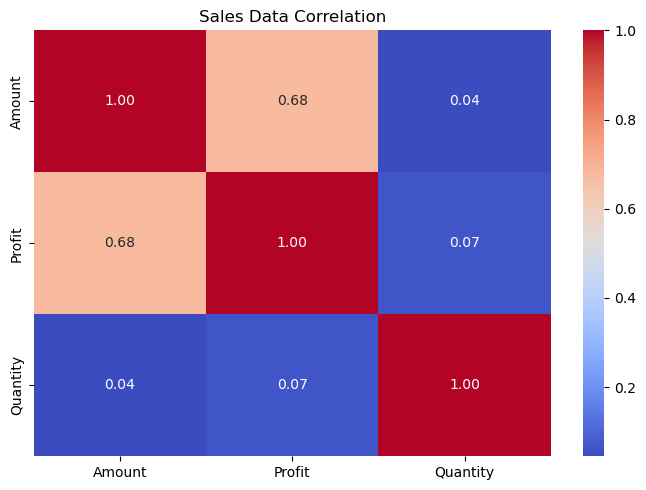

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    clean_data[["Amount", "Profit", "Quantity"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Sales Data Correlation")
plt.tight_layout()
plt.show()

In [ ]:
import sqlite3
import pandas as pd
import numpy as np
import re
from pathlib import Path

# Set paths relative to your notebook
database_folder = Path("../database")
database_folder.mkdir(parents=True, exist_ok=True)

db_path = database_folder / "sales.db"

# Copy the cleaned data
sql_df = clean_data.copy()

# Convert column names into SQL-friendly names
sql_df.columns = [
    re.sub(r"_+", "_",
           re.sub(r"[^a-zA-Z0-9]+", "_", col.strip().lower())
    ).strip("_")
    for col in sql_df.columns
]

# Store data in SQLite
with sqlite3.connect(db_path) as conn:
    sql_df.to_sql("sales", conn, if_exists="replace", index=False)

print("Database created:", db_path.resolve())
print("Rows inserted:", len(sql_df))
print("Table name: sales")

Database created: C:\Users\USER\Documents\sales_data_analysis\database\sales.db
Rows inserted: 1194
Table name: sales


In [ ]:
with sqlite3.connect(db_path) as conn:
    tables = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type='table';",
        conn
    )

    print("Tables in database:")
    display(tables)

    preview = pd.read_sql_query(
        "SELECT * FROM sales LIMIT 5;",
        conn
    )

    print("First five database records:")
    display(preview)

Tables in database:


,name
0,sales


First five database records:


,order_id,amount,profit,quantity,category,sub_category,paymentmode,order_date,customername,state,city,year_month
0,B-26776,9726,1275,5,Electronics,Electronic Games,UPI,2023-06-27 00:00:00,David Padilla,Florida,Miami,2023-06
1,B-26776,9726,1275,5,Electronics,Electronic Games,UPI,2024-12-27 00:00:00,Connor Morgan,Illinois,Chicago,2024-12
2,B-26776,9726,1275,5,Electronics,Electronic Games,UPI,2021-07-25 00:00:00,Robert Stone,New York,Buffalo,2021-07
3,B-26776,4975,1330,14,Electronics,Printers,UPI,2023-06-27 00:00:00,David Padilla,Florida,Miami,2023-06
4,B-26776,4975,1330,14,Electronics,Printers,UPI,2024-12-27 00:00:00,Connor Morgan,Illinois,Chicago,2024-12


In [ ]:
def run_sql(query):
    with sqlite3.connect(db_path) as conn:
        return pd.read_sql_query(query, conn)

In [ ]:
query = """
SELECT
    SUM(amount) AS total_sales,
    SUM(profit) AS total_profit,
    SUM(quantity) AS total_quantity
FROM sales;
"""

display(run_sql(query))

,total_sales,total_profit,total_quantity
0,6182639,1610697,12745


In [ ]:
query = """
SELECT
    COUNT(*) AS total_records,
    COUNT(DISTINCT order_id) AS distinct_order_ids
FROM sales;
"""

display(run_sql(query))

,total_records,distinct_order_ids
0,1194,547


In [ ]:
query = """
SELECT
    category,
    SUM(amount) AS total_sales,
    SUM(profit) AS total_profit
FROM sales
GROUP BY category
ORDER BY total_sales DESC;
"""

display(run_sql(query))

,category,total_sales,total_profit
0,Office Supplies,2089510,551575
1,Electronics,2054456,518580
2,Furniture,2038673,540542


In [ ]:
query = """
SELECT
    sub_category,
    SUM(amount) AS total_sales,
    SUM(profit) AS total_profit
FROM sales
GROUP BY sub_category
ORDER BY total_sales DESC
LIMIT 10;
"""

display(run_sql(query))

,sub_category,total_sales,total_profit
0,Markers,627875,174749
1,Tables,625177,156796
2,Sofas,568367,142854
3,Printers,566359,146259
4,Electronic Games,565092,148454
5,Pens,552269,129846
6,Paper,524755,149723
7,Phones,503055,113607
8,Chairs,431964,122892
9,Laptops,419950,110260


In [ ]:
query = """
SELECT
    state,
    SUM(amount) AS total_sales,
    SUM(profit) AS total_profit
FROM sales
WHERE state IS NOT NULL
GROUP BY state
ORDER BY total_sales DESC;
"""

display(run_sql(query))

,state,total_sales,total_profit
0,New York,1130048,308506
1,Florida,1091174,308706
2,California,1086436,278814
3,Texas,1011475,257780
4,Illinois,978738,240372
5,Ohio,884768,216519


In [ ]:
query = """
SELECT
    year_month,
    SUM(amount) AS total_sales,
    SUM(profit) AS total_profit
FROM sales
WHERE year_month IS NOT NULL
GROUP BY year_month
ORDER BY year_month;
"""

display(run_sql(query))

,year_month,total_sales,total_profit
0,2020-03,22991,6192
1,2020-04,133385,36156
2,2020-05,113287,24294
3,2020-06,46900,9489
4,2020-07,38556,12008
...,...,...,...
56,2024-11,60976,15657
57,2024-12,98879,20981
58,2025-01,112906,38595
59,2025-02,84712,28151


In [ ]:
query = """
SELECT
    SUM(amount) / COUNT(DISTINCT order_id) AS sales_per_distinct_order_id
FROM sales
WHERE order_id IS NOT NULL;
"""

display(run_sql(query))

,sales_per_distinct_order_id
0,11302
